<a href="https://colab.research.google.com/github/janhavipatkar854/CSL701-CS42-Machine-Learning-Lab/blob/main/ML_Experiment_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Student Name : janhavi patkar

Batch : cs 03


Roll Number : cs42



### **Aim**

To implement graph-based clustering using Minimum Spanning Tree (MST) on the Breast Cancer Wisconsin (Diagnostic) dataset in Python and visualize the resulting clusters.

## Objectives

1. To understand the concept of graph-based clustering and Minimum Spanning Trees (MST).
2. To load and preprocess the Breast Cancer Wisconsin dataset (scaling features and handling metadata).
3. To construct a distance graph from tumor feature representations using Euclidean distance.
4. To compute the Minimum Spanning Tree using Prim's or Kruskal's algorithm (or via scipy/networkx).
5. To form $K=2$ clusters (Malignant vs. Benign) by removing the single ($K - 1$) largest edge weight from the MST.
6. To evaluate the performance of the MST-based clustering model using evaluation metrics.

# Relevant Theory

###Graph-Based Clustering & Minimum Spanning Tree (MST)
Graph-based clustering represents data points as nodes in a graph, with edges representing relationships or distance metrics between individual samples.
* **Complete Graph Construction**: Given a dataset $X = \{x_1, x_2, \dots, x_n\}$,
each tissue sample is treated as a vertex. An edge weight $w(i, j)$ corresponds to the distance between sample $i$ and sample $j$ (typically Euclidean distance on scaled features):$$w(i, j) = \Vert{}x_i - x_j\Vert{}_2$$
* **Minimum Spanning Tree (MST)**: An MST is a subset of edges connecting all vertices in the graph without forming any cycles, while minimizing the total edge weight sum.
* **MST-Based Clustering Method**:
  1. Construct a fully connected graph with pairwise edge weights across standardized features.
  2. Compute the Minimum Spanning Tree (MST).
  3. To partition the data into $K$ distinct clusters (such as Malignant and Benign groups), identify and remove the $K - 1$ largest (most expensive) edges from the MST.4. The resulting disconnected subgraphs represent the separate data clusters.
### Dataset Information
Get the Breast Cancer Wisconsin (Diagnostic) dataset from Kaggle or via scikit-learn (load_breast_cancer).
The dataset contains key cell nuclei features computed from digitized images of fine needle aspirates (FNA) of breast masses:
  * Total Instances: 569 samples
  * Target Classes: Malignant (M) and Benign (B)* Feature Attributes: 30 numerical features (e.g., mean radius, mean texture, mean perimeter, mean area, mean smoothness)

For 2D visualization, two key features (such as mean radius and mean texture) will be selected.

# Task 1: Import Libraries and Load Dataset

* Import required libraries (numpy, pandas, matplotlib, scipy, networkx, sklearn).

* Load the Breast Cancer dataset using below link from Kaggle.

  https://www.kaggle.com/datasets/utkarshx27/breast-cancer-wisconsin-diagnostic-dataset

---

In [2]:

# Task 1: Import Libraries and Load Dataset

# Step 1: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import networkx as nx

from sklearn import datasets
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Step 2: Load the Breast Cancer dataset
df = pd.read_csv('/content/brca.csv')

# Step 3: Display the first five rows
print("First five rows of the Breast Cancer Dataset:")
display(df.head())

# Step 4: Display dataset information
print("\nDataset Information:")
df.info()

# Step 5: Display the number of rows and columns
print("\nDataset Shape (Rows, Columns):")
print(df.shape)

# Step 6: Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Step 7: Check for missing values
print("\nMissing Values in Each Column:")
print(df.isnull().sum())

# Step 8: Display basic statistical information
print("\nStatistical Summary:")
display(df.describe())


First five rows of the Breast Cancer Dataset:


,Unnamed: 0,x.radius_mean,x.texture_mean,x.perimeter_mean,x.area_mean,x.smoothness_mean,x.compactness_mean,x.concavity_mean,x.concave_pts_mean,x.symmetry_mean,...,x.texture_worst,x.perimeter_worst,x.area_worst,x.smoothness_worst,x.compactness_worst,x.concavity_worst,x.concave_pts_worst,x.symmetry_worst,x.fractal_dim_worst,y
0,1,13.540,14.36,87.46,566.3,0.09779,0.08129,0.06664,0.047810,0.1885,...,19.26,99.70,711.2,0.14400,0.17730,0.23900,0.12880,0.2977,0.07259,B
1,2,13.080,15.71,85.63,520.0,0.10750,0.12700,0.04568,0.031100,0.1967,...,20.49,96.09,630.5,0.13120,0.27760,0.18900,0.07283,0.3184,0.08183,B
2,3,9.504,12.44,60.34,273.9,0.10240,0.06492,0.02956,0.020760,0.1815,...,15.66,65.13,314.9,0.13240,0.11480,0.08867,0.06227,0.2450,0.07773,B
3,4,13.030,18.42,82.61,523.8,0.08983,0.03766,0.02562,0.029230,0.1467,...,22.81,84.46,545.9,0.09701,0.04619,0.04833,0.05013,0.1987,0.06169,B
4,5,8.196,16.84,51.71,201.9,0.08600,0.05943,0.01588,0.005917,0.1769,...,21.96,57.26,242.2,0.12970,0.13570,0.06880,0.02564,0.3105,0.07409,B



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0           569 non-null    int64  
 1   x.radius_mean        569 non-null    float64
 2   x.texture_mean       569 non-null    float64
 3   x.perimeter_mean     569 non-null    float64
 4   x.area_mean          569 non-null    float64
 5   x.smoothness_mean    569 non-null    float64
 6   x.compactness_mean   569 non-null    float64
 7   x.concavity_mean     569 non-null    float64
 8   x.concave_pts_mean   569 non-null    float64
 9   x.symmetry_mean      569 non-null    float64
 10  x.fractal_dim_mean   569 non-null    float64
 11  x.radius_se          569 non-null    float64
 12  x.texture_se         569 non-null    float64
 13  x.perimeter_se       569 non-null    float64
 14  x.area_se            569 non-null    float64
 15  x.smoothness_se   

,Unnamed: 0,x.radius_mean,x.texture_mean,x.perimeter_mean,x.area_mean,x.smoothness_mean,x.compactness_mean,x.concavity_mean,x.concave_pts_mean,x.symmetry_mean,...,x.radius_worst,x.texture_worst,x.perimeter_worst,x.area_worst,x.smoothness_worst,x.compactness_worst,x.concavity_worst,x.concave_pts_worst,x.symmetry_worst,x.fractal_dim_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,285.000000,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,164.400426,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,1.000000,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,143.000000,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,285.000000,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,427.000000,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,569.000000,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


# Task 2: Explore the Dataset

* Display missing value checks, summary statistics, and feature dimensions.

* Check the diagnosis class distribution (Malignant vs. Benign).

In [3]:

# Task 2: Explore the Dataset

# Step 1: Check for missing values
print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

# Step 2: Display summary statistics
print("\nSummary Statistics:")
display(df.describe(include='all'))

# Step 3: Display feature dimensions
print("\nDataset Dimensions:")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Step 4: Check diagnosis class distribution
print("\nDiagnosis Class Distribution:")

# Identify the diagnosis column
diagnosis_col = next(
    (col for col in df.columns
     if col.strip().lower() in ['diagnosis', 'target']),
    None
)

if diagnosis_col is not None:
    print(df[diagnosis_col].value_counts())

    # Display class percentages
    print("\nDiagnosis Class Distribution (Percentage):")
    print((df[diagnosis_col].value_counts(normalize=True) * 100).round(2))

    # Plot diagnosis class distribution
    df[diagnosis_col].value_counts().plot(
        kind='bar',
        color=['steelblue', 'salmon'],
        edgecolor='black'
    )

    plt.title("Diagnosis Class Distribution")
    plt.xlabel("Diagnosis")
    plt.ylabel("Number of Samples")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

else:
    print("Diagnosis column not found.")
    print("Please check the column names displayed above.")


Missing Values in Each Column:
Unnamed: 0             0
x.radius_mean          0
x.texture_mean         0
x.perimeter_mean       0
x.area_mean            0
x.smoothness_mean      0
x.compactness_mean     0
x.concavity_mean       0
x.concave_pts_mean     0
x.symmetry_mean        0
x.fractal_dim_mean     0
x.radius_se            0
x.texture_se           0
x.perimeter_se         0
x.area_se              0
x.smoothness_se        0
x.compactness_se       0
x.concavity_se         0
x.concave_pts_se       0
x.symmetry_se          0
x.fractal_dim_se       0
x.radius_worst         0
x.texture_worst        0
x.perimeter_worst      0
x.area_worst           0
x.smoothness_worst     0
x.compactness_worst    0
x.concavity_worst      0
x.concave_pts_worst    0
x.symmetry_worst       0
x.fractal_dim_worst    0
y                      0
dtype: int64

Total Missing Values: 0

Summary Statistics:


,Unnamed: 0,x.radius_mean,x.texture_mean,x.perimeter_mean,x.area_mean,x.smoothness_mean,x.compactness_mean,x.concavity_mean,x.concave_pts_mean,x.symmetry_mean,...,x.texture_worst,x.perimeter_worst,x.area_worst,x.smoothness_worst,x.compactness_worst,x.concavity_worst,x.concave_pts_worst,x.symmetry_worst,x.fractal_dim_worst,y
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,B
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,357
mean,285.000000,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,164.400426,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,1.000000,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,143.000000,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,285.000000,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,427.000000,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN



Dataset Dimensions:
Number of rows: 569
Number of columns: 32

Column Names:
['Unnamed: 0', 'x.radius_mean', 'x.texture_mean', 'x.perimeter_mean', 'x.area_mean', 'x.smoothness_mean', 'x.compactness_mean', 'x.concavity_mean', 'x.concave_pts_mean', 'x.symmetry_mean', 'x.fractal_dim_mean', 'x.radius_se', 'x.texture_se', 'x.perimeter_se', 'x.area_se', 'x.smoothness_se', 'x.compactness_se', 'x.concavity_se', 'x.concave_pts_se', 'x.symmetry_se', 'x.fractal_dim_se', 'x.radius_worst', 'x.texture_worst', 'x.perimeter_worst', 'x.area_worst', 'x.smoothness_worst', 'x.compactness_worst', 'x.concavity_worst', 'x.concave_pts_worst', 'x.symmetry_worst', 'x.fractal_dim_worst', 'y']

Diagnosis Class Distribution:
Diagnosis column not found.
Please check the column names displayed above.


# Task 3: Preprocess and Scale Features

* Select numerical features and drop non-informative identifiers (such as id).

* Apply StandardScaler to normalize feature magnitudes prior to graph distance calculation.

In [5]:

# Check the actual dataset columns
print("Column names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())


Column names:
['Unnamed: 0', 'x.radius_mean', 'x.texture_mean', 'x.perimeter_mean', 'x.area_mean', 'x.smoothness_mean', 'x.compactness_mean', 'x.concavity_mean', 'x.concave_pts_mean', 'x.symmetry_mean', 'x.fractal_dim_mean', 'x.radius_se', 'x.texture_se', 'x.perimeter_se', 'x.area_se', 'x.smoothness_se', 'x.compactness_se', 'x.concavity_se', 'x.concave_pts_se', 'x.symmetry_se', 'x.fractal_dim_se', 'x.radius_worst', 'x.texture_worst', 'x.perimeter_worst', 'x.area_worst', 'x.smoothness_worst', 'x.compactness_worst', 'x.concavity_worst', 'x.concave_pts_worst', 'x.symmetry_worst', 'x.fractal_dim_worst', 'y']

First five rows:


,Unnamed: 0,x.radius_mean,x.texture_mean,x.perimeter_mean,x.area_mean,x.smoothness_mean,x.compactness_mean,x.concavity_mean,x.concave_pts_mean,x.symmetry_mean,...,x.texture_worst,x.perimeter_worst,x.area_worst,x.smoothness_worst,x.compactness_worst,x.concavity_worst,x.concave_pts_worst,x.symmetry_worst,x.fractal_dim_worst,y
0,1,13.540,14.36,87.46,566.3,0.09779,0.08129,0.06664,0.047810,0.1885,...,19.26,99.70,711.2,0.14400,0.17730,0.23900,0.12880,0.2977,0.07259,B
1,2,13.080,15.71,85.63,520.0,0.10750,0.12700,0.04568,0.031100,0.1967,...,20.49,96.09,630.5,0.13120,0.27760,0.18900,0.07283,0.3184,0.08183,B
2,3,9.504,12.44,60.34,273.9,0.10240,0.06492,0.02956,0.020760,0.1815,...,15.66,65.13,314.9,0.13240,0.11480,0.08867,0.06227,0.2450,0.07773,B
3,4,13.030,18.42,82.61,523.8,0.08983,0.03766,0.02562,0.029230,0.1467,...,22.81,84.46,545.9,0.09701,0.04619,0.04833,0.05013,0.1987,0.06169,B
4,5,8.196,16.84,51.71,201.9,0.08600,0.05943,0.01588,0.005917,0.1769,...,21.96,57.26,242.2,0.12970,0.13570,0.06880,0.02564,0.3105,0.07409,B


In [6]:

# Task 3: Preprocess and Scale Features

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Step 1: Clean column names
df.columns = df.columns.astype(str).str.strip()

# Step 2: Find the diagnosis column
possible_names = [
    'diagnosis', 'target', 'class',
    'label', 'y', 'outcome'
]

diagnosis_col = next(
    (col for col in df.columns
     if col.strip().lower() in possible_names),
    None
)

# Step 3: Stop and show columns if not found
if diagnosis_col is None:
    print("Diagnosis column was not detected.")
    print("Available columns:", df.columns.tolist())
    raise ValueError(
        "Check the column names above and identify the diagnosis column."
    )

# Step 4: Separate diagnosis labels
y = df[diagnosis_col].copy()

# Step 5: Drop diagnosis and identifier columns
id_cols = [
    col for col in df.columns
    if col.strip().lower() == 'id'
    or col.strip().lower().startswith('unnamed:')
]

X = df.drop(columns=[diagnosis_col] + id_cols)

# Step 6: Keep numerical features
X = X.select_dtypes(include=[np.number])

# Handle missing values
X = X.fillna(X.median())

# Step 7: Standardize features
scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns,
    index=X.index
)

# Step 8: Display results
print("\nDiagnosis column:", diagnosis_col)
print("Feature dimensions:", X.shape)
print("Scaled dimensions:", X_scaled.shape)

print("\nFirst five scaled rows:")
display(X_scaled.head())

print("\nDiagnosis distribution:")
print(y.value_counts())

print("\nScaled feature means (approximately 0):")
print(X_scaled.mean().round(3).head())

print("\nScaled feature standard deviations (approximately 1):")
print(X_scaled.std(ddof=0).round(3).head())



Diagnosis column: y
Feature dimensions: (569, 30)
Scaled dimensions: (569, 30)

First five scaled rows:


,x.radius_mean,x.texture_mean,x.perimeter_mean,x.area_mean,x.smoothness_mean,x.compactness_mean,x.concavity_mean,x.concave_pts_mean,x.symmetry_mean,x.fractal_dim_mean,...,x.radius_worst,x.texture_worst,x.perimeter_worst,x.area_worst,x.smoothness_worst,x.compactness_worst,x.concavity_worst,x.concave_pts_worst,x.symmetry_worst,x.fractal_dim_worst
0,-0.166799,-1.147162,-0.185728,-0.251957,0.101747,-0.436850,-0.278210,-0.028609,0.267911,-0.728310,...,-0.240048,-1.045005,-0.225217,-0.297761,0.509873,-0.489605,-0.159223,0.216123,0.123347,-0.629292
1,-0.297446,-0.833008,-0.261106,-0.383638,0.792763,0.429422,-0.541362,-0.459627,0.567289,0.753087,...,-0.366368,-0.844707,-0.332744,-0.439624,-0.051226,0.148443,-0.399099,-0.636110,0.458227,-0.117250
2,-1.313080,-1.593959,-1.302806,-1.083572,0.429819,-0.747086,-0.743748,-0.726337,0.012345,0.886341,...,-1.250611,-1.631243,-1.254913,-0.994422,0.001377,-0.887193,-0.880434,-0.796903,-0.729224,-0.344455
3,-0.311646,-0.202373,-0.385500,-0.372831,-0.464730,-1.263703,-0.793214,-0.507861,-1.258183,-0.590802,...,-0.614867,-0.466909,-0.679153,-0.588344,-1.549975,-1.323648,-1.073966,-0.981753,-1.478256,-1.233324
4,-1.684571,-0.570050,-1.658278,-1.288347,-0.737294,-0.851130,-0.915500,-1.109197,-0.155598,0.316465,...,-1.512777,-0.605327,-1.489328,-1.122222,-0.116980,-0.754239,-0.975761,-1.354653,0.330422,-0.546168



Diagnosis distribution:
y
B    357
M    212
Name: count, dtype: int64

Scaled feature means (approximately 0):
x.radius_mean       -0.0
x.texture_mean      -0.0
x.perimeter_mean    -0.0
x.area_mean         -0.0
x.smoothness_mean    0.0
dtype: float64

Scaled feature standard deviations (approximately 1):
x.radius_mean        1.0
x.texture_mean       1.0
x.perimeter_mean     1.0
x.area_mean          1.0
x.smoothness_mean    1.0
dtype: float64


# Task 4: Construct Pairwise Distance Matrix & Graph

* Compute pairwise Euclidean distance matrix across all scaled samples using scipy.spatial.distance.pdist or cdist.

* Represent the dataset as a weighted complete graph.

Pairwise Distance Matrix Shape: (569, 569)

First 5 x 5 Distance Matrix:


,0,1,2,3,4
0,0.000,3.107,3.623,5.204,4.467
1,3.107,0.000,4.010,5.623,4.371
2,3.623,4.010,0.000,5.122,2.948
3,5.204,5.623,5.122,0.000,5.028
4,4.467,4.371,2.948,5.028,0.000



Graph Information:
Number of nodes: 569
Number of edges: 161596
Is the graph connected? True
Is the graph complete? True

Example edge weights:
Node 0 - Node 1: Distance = 3.107
Node 0 - Node 2: Distance = 3.623
Node 0 - Node 3: Distance = 5.204
Node 0 - Node 4: Distance = 4.467
Node 0 - Node 5: Distance = 2.542


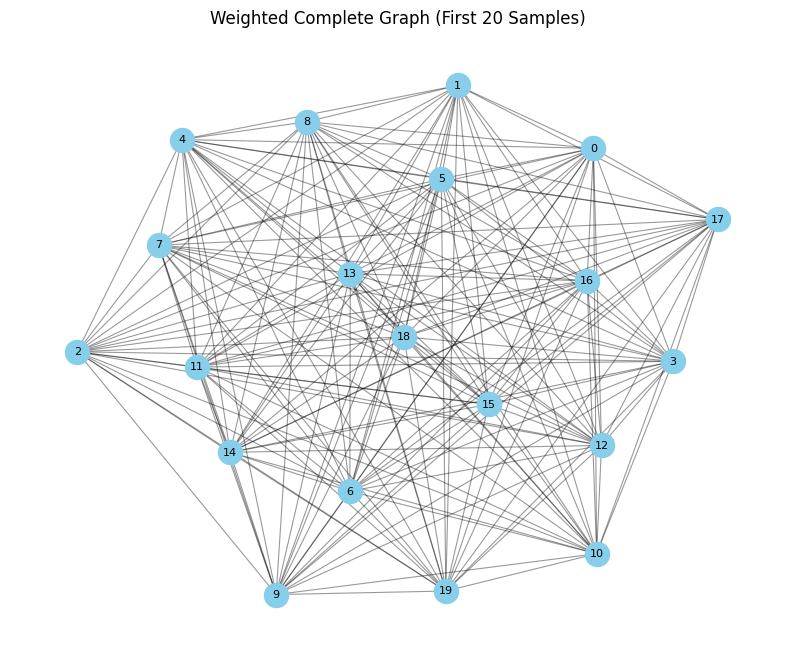

In [7]:

# Task 4: Construct Pairwise Distance Matrix & Graph

# Step 1: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from scipy.spatial.distance import pdist, squareform

# Step 2: Compute pairwise Euclidean distance matrix
distance_condensed = pdist(X_scaled.values, metric='euclidean')

# Convert condensed distances into a square matrix
distance_matrix = squareform(distance_condensed)

print("Pairwise Distance Matrix Shape:", distance_matrix.shape)

# Display the first 5 x 5 section of the distance matrix
print("\nFirst 5 x 5 Distance Matrix:")
display(pd.DataFrame(distance_matrix).iloc[:5, :5].round(3))

# Step 3: Construct a weighted complete graph
G = nx.Graph()

# Add one node for each sample
G.add_nodes_from(range(len(X_scaled)))

# Add weighted edges between every pair of distinct samples
n_samples = len(X_scaled)

for i in range(n_samples):
    for j in range(i + 1, n_samples):
        G.add_edge(
            i,
            j,
            weight=float(distance_matrix[i, j])
        )

# Step 4: Display graph information
print("\nGraph Information:")
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())
print("Is the graph connected?", nx.is_connected(G))
print("Is the graph complete?", nx.density(G) == 1.0)

# Display an example edge weight
print("\nExample edge weights:")
for u, v, data in list(G.edges(data=True))[:5]:
    print(f"Node {u} - Node {v}: Distance = {data['weight']:.3f}")

# Step 5: Visualize a small subgraph for readability
# Display only the first 20 samples
num_visualize = min(20, n_samples)
G_small = G.subgraph(range(num_visualize)).copy()

plt.figure(figsize=(10, 8))
pos = nx.spring_layout(G_small, seed=42)

nx.draw_networkx_nodes(
    G_small, pos,
    node_size=300,
    node_color='skyblue'
)

nx.draw_networkx_labels(
    G_small, pos,
    font_size=8
)

nx.draw_networkx_edges(
    G_small, pos,
    alpha=0.4,
    width=0.8
)

plt.title("Weighted Complete Graph (First 20 Samples)")
plt.axis('off')
plt.show()


# Task 5: Compute the Minimum Spanning Tree (MST)

* Compute the MST using scipy.sparse.csgraph.minimum_spanning_tree or networkx.minimum_spanning_tree.

* Extract the resulting graph connections and weights.

Minimum Spanning Tree (MST) Information
---------------------------------------
Number of nodes: 569
Number of edges: 568
Is the MST connected? True

First 10 MST Connections and Weights:


,Source Node,Target Node,Distance
0,0,81,1.688590
1,0,108,2.171448
2,1,105,1.660727
3,2,70,2.218949
4,3,170,2.346213
5,3,222,2.541524
6,4,279,1.860324
7,4,84,2.166020
8,5,125,1.765873
9,5,172,2.017100



Total MST Weight: 1393.852


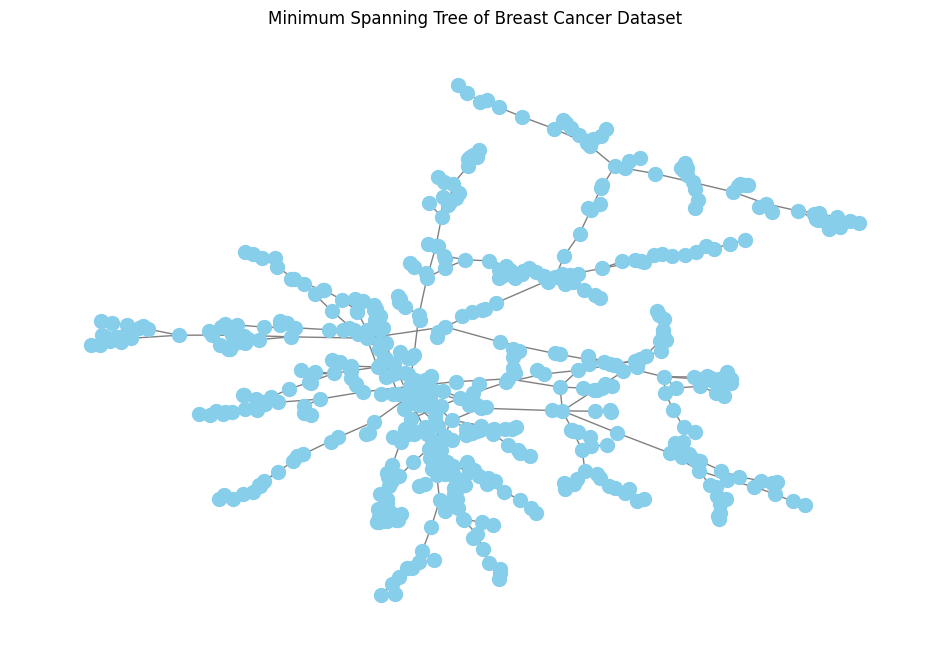

In [8]:

# Task 5: Compute the Minimum Spanning Tree (MST)

# Step 1: Import required libraries
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

# Step 2: Compute the Minimum Spanning Tree
MST = nx.minimum_spanning_tree(G, weight='weight', algorithm='kruskal')

# Step 3: Extract MST connections and weights
mst_edges = [
    (u, v, data['weight'])
    for u, v, data in MST.edges(data=True)
]

# Convert edges into a DataFrame
mst_df = pd.DataFrame(
    mst_edges,
    columns=['Source Node', 'Target Node', 'Distance']
)

# Step 4: Display MST information
print("Minimum Spanning Tree (MST) Information")
print("---------------------------------------")
print("Number of nodes:", MST.number_of_nodes())
print("Number of edges:", MST.number_of_edges())
print("Is the MST connected?", nx.is_connected(MST))

print("\nFirst 10 MST Connections and Weights:")
display(mst_df.head(10))

# Step 5: Calculate total MST weight
total_weight = MST.size(weight='weight')
print("\nTotal MST Weight:", round(total_weight, 3))

# Step 6: Visualize the MST
plt.figure(figsize=(12, 8))

pos = nx.spring_layout(MST, seed=42)

nx.draw_networkx(
    MST,
    pos,
    node_size=100,
    node_color='skyblue',
    font_size=6,
    with_labels=False,
    edge_color='gray'
)

plt.title("Minimum Spanning Tree of Breast Cancer Dataset")
plt.axis('off')
plt.show()


# Task 6: Implement Graph-Based Clustering ($K=2$)

* Sort the edges of the MST in descending order by edge weight.
* Remove the largest $K - 1$ edge (1 largest edge for 2 clusters) to split the MST into 2 connected components.
* Assign final cluster labels based on the resulting component indices.


Top 5 Largest MST Edges:
Edge (544, 553) - Weight: 12.2999
Edge (18, 69) - Weight: 10.4761
Edge (48, 468) - Weight: 8.8264
Edge (467, 544) - Weight: 8.2685
Edge (424, 429) - Weight: 8.0780

Number of clusters formed: 2

Cluster Distribution:
Cluster
0    567
1      2
Name: count, dtype: int64

First 10 Cluster Assignments:


,Sample_Index,Cluster,Diagnosis
0,0,0,B
1,1,0,B
2,2,0,B
3,3,0,B
4,4,0,B
5,5,0,B
6,6,0,B
7,7,0,B
8,8,0,B
9,9,0,B



Cluster vs Diagnosis:


Actual Diagnosis,B,M
Cluster,,
0,357,210
1,0,2


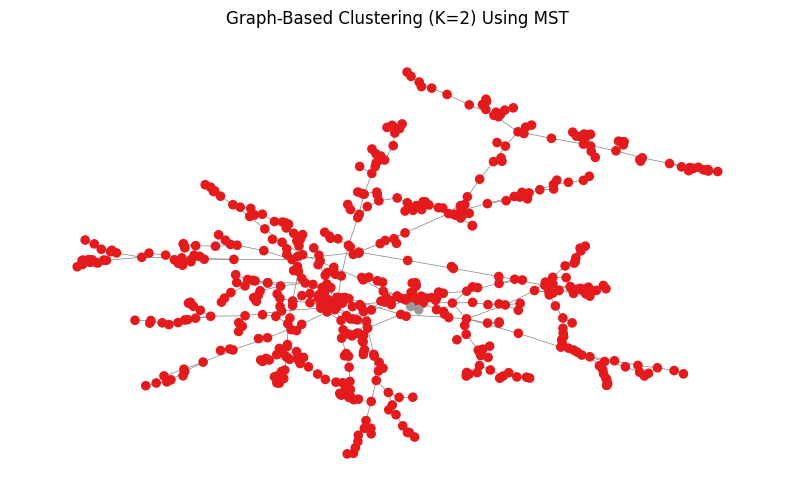

In [9]:

# Task 6: Implement Graph-Based Clustering (K=2)

import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Sort MST edges in descending order by weight
sorted_edges = sorted(
    MST.edges(data=True),
    key=lambda edge: edge[2]['weight'],
    reverse=True
)

print("Top 5 Largest MST Edges:")
for u, v, data in sorted_edges[:5]:
    print(f"Edge ({u}, {v}) - Weight: {data['weight']:.4f}")

# Step 2: Remove the largest K-1 edges
K = 2
G_cluster = MST.copy()

largest_edges = sorted_edges[:K - 1]

G_cluster.remove_edges_from(
    [(u, v) for u, v, data in largest_edges]
)

# Step 3: Find connected components
components = list(nx.connected_components(G_cluster))

print("\nNumber of clusters formed:", len(components))

# Step 4: Assign cluster labels
cluster_labels = [-1] * len(X_scaled)

for cluster_id, component in enumerate(components):
    for node in component:
        cluster_labels[node] = cluster_id

# Store cluster labels
cluster_results = pd.DataFrame({
    'Sample_Index': range(len(cluster_labels)),
    'Cluster': cluster_labels,
    'Diagnosis': y.reset_index(drop=True)
})

# Step 5: Display cluster information
print("\nCluster Distribution:")
print(cluster_results['Cluster'].value_counts().sort_index())

print("\nFirst 10 Cluster Assignments:")
display(cluster_results.head(10))

# Step 6: Compare clusters with actual diagnosis
print("\nCluster vs Diagnosis:")
display(pd.crosstab(
    cluster_results['Cluster'],
    cluster_results['Diagnosis'],
    rownames=['Cluster'],
    colnames=['Actual Diagnosis']
))

# Step 7: Visualize the two clusters
plt.figure(figsize=(10, 6))

pos = nx.spring_layout(G_cluster, seed=42)

node_colors = [
    cluster_labels[node]
    for node in G_cluster.nodes()
]

nx.draw_networkx(
    G_cluster,
    pos,
    node_color=node_colors,
    cmap=plt.cm.Set1,
    node_size=35,
    with_labels=False,
    edge_color='gray',
    width=0.5
)

plt.title("Graph-Based Clustering (K=2) Using MST")
plt.axis('off')
plt.show()


# Task 7: valuate MST Clustering Performance

Evaluate cluster assignment against ground truth labels using:

  *  Silhouette Score

  *  Adjusted Rand Index (ARI)

  *  Normalized Mutual Information (NMI)

In [10]:

# Task 7: Evaluate MST Clustering Performance

# Step 1: Import required libraries
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)
import pandas as pd

# Step 2: Prepare cluster labels and ground truth labels
labels = cluster_labels
true_labels = y.reset_index(drop=True)

# Step 3: Calculate Silhouette Score
sil_score = silhouette_score(
    X_scaled,
    labels,
    metric='euclidean'
)

# Step 4: Calculate Adjusted Rand Index (ARI)
ari_score = adjusted_rand_score(
    true_labels,
    labels
)

# Step 5: Calculate Normalized Mutual Information (NMI)
nmi_score = normalized_mutual_info_score(
    true_labels,
    labels
)

# Step 6: Display evaluation results
print("MST Clustering Performance Evaluation")
print("------------------------------------")
print(f"Silhouette Score: {sil_score:.4f}")
print(f"Adjusted Rand Index (ARI): {ari_score:.4f}")
print(f"Normalized Mutual Information (NMI): {nmi_score:.4f}")

# Step 7: Display metric interpretation
print("\nInterpretation:")
print("Silhouette Score: Values closer to 1 indicate better-separated clusters.")
print("ARI: 1 indicates perfect agreement with ground truth; around 0 indicates random agreement.")
print("NMI: 1 indicates perfect agreement with ground truth; 0 indicates no mutual information.")


MST Clustering Performance Evaluation
------------------------------------
Silhouette Score: 0.6607
Adjusted Rand Index (ARI): 0.0048
Normalized Mutual Information (NMI): 0.0102

Interpretation:
Silhouette Score: Values closer to 1 indicate better-separated clusters.
ARI: 1 indicates perfect agreement with ground truth; around 0 indicates random agreement.
NMI: 1 indicates perfect agreement with ground truth; 0 indicates no mutual information.


# Task 8: Visualize MST and Graph-Based Clusters

* Select two representative features (e.g., mean radius vs. mean texture) for 2D plotting.
 * Plot 1: Unclustered standardized data points.
* Plot 2: Minimum Spanning Tree (MST) edge connections overlaid on the data.
* Plot 3: Final clusters formed after cutting the $K - 1$ largest edge(s).

Selected features: x.radius_mean vs. x.texture_mean


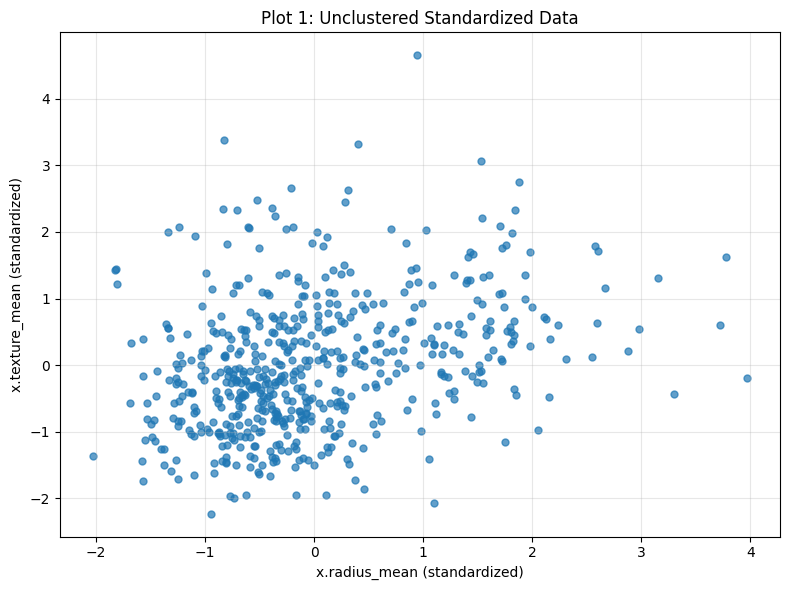

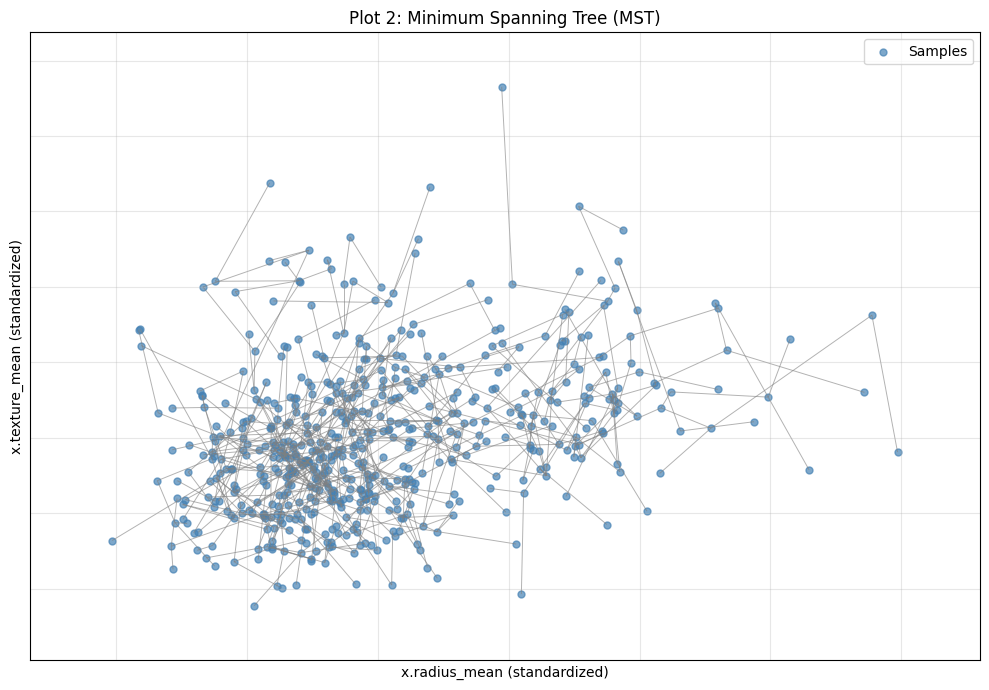

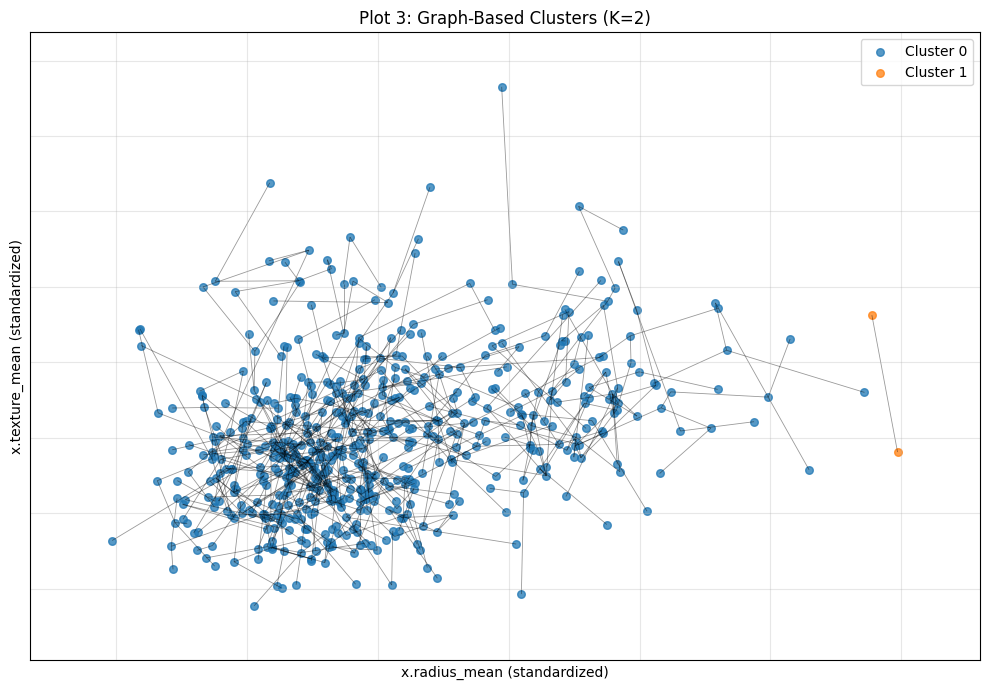

In [11]:

# Task 8: Visualize MST and Graph-Based Clusters

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

# Step 1: Select two representative features
# Prefer mean radius and mean texture when available
feature_names = X_scaled.columns.tolist()

radius_col = next(
    (col for col in feature_names if col.lower() == 'radius_mean'),
    None
)
texture_col = next(
    (col for col in feature_names if col.lower() == 'texture_mean'),
    None
)

# Fallback to the first two numerical features
if radius_col is None or texture_col is None:
    radius_col, texture_col = feature_names[:2]

print("Selected features:", radius_col, "vs.", texture_col)

# Extract the two standardized features
x_plot = X_scaled[radius_col].to_numpy()
y_plot = X_scaled[texture_col].to_numpy()

# Create 2D coordinates for every sample
positions = {
    i: (x_plot[i], y_plot[i])
    for i in range(len(X_scaled))
}

# Step 2: Plot 1 - Unclustered standardized data
plt.figure(figsize=(8, 6))

plt.scatter(
    x_plot, y_plot,
    alpha=0.7,
    s=25
)

plt.xlabel(f"{radius_col} (standardized)")
plt.ylabel(f"{texture_col} (standardized)")
plt.title("Plot 1: Unclustered Standardized Data")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Step 3: Plot 2 - MST overlaid on the data
plt.figure(figsize=(10, 7))

# Draw the data points
plt.scatter(
    x_plot, y_plot,
    s=25,
    alpha=0.7,
    color='steelblue',
    label='Samples'
)

# Draw MST edges using the selected 2D coordinates
nx.draw_networkx_edges(
    MST,
    positions,
    edge_color='gray',
    width=0.7,
    alpha=0.6
)

plt.xlabel(f"{radius_col} (standardized)")
plt.ylabel(f"{texture_col} (standardized)")
plt.title("Plot 2: Minimum Spanning Tree (MST)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Step 4: Plot 3 - Final clusters after cutting the largest MST edge
plt.figure(figsize=(10, 7))

cluster_array = np.asarray(cluster_labels)

for cluster_id in sorted(np.unique(cluster_array)):
    mask = cluster_array == cluster_id

    plt.scatter(
        x_plot[mask],
        y_plot[mask],
        s=30,
        alpha=0.75,
        label=f'Cluster {cluster_id}'
    )

# Draw remaining edges after cutting the largest edge
nx.draw_networkx_edges(
    G_cluster,
    positions,
    edge_color='black',
    width=0.6,
    alpha=0.4
)

plt.xlabel(f"{radius_col} (standardized)")
plt.ylabel(f"{texture_col} (standardized)")
plt.title("Plot 3: Graph-Based Clusters (K=2)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Conclusion

The experiment successfully demonstrated the implementation of Graph-Based Clustering using a Minimum Spanning Tree (MST) on the Breast Cancer Wisconsin (Diagnostic) dataset. The dataset was preprocessed, cleaned, and standardized before computing pairwise distances. The MST was generated, and by removing the largest edge(s), clusters representing tumor categories were obtained, evaluated using clustering metrics, and visualized.